  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (to

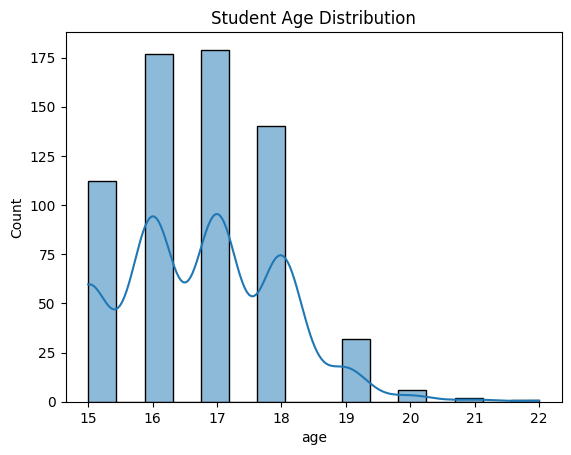

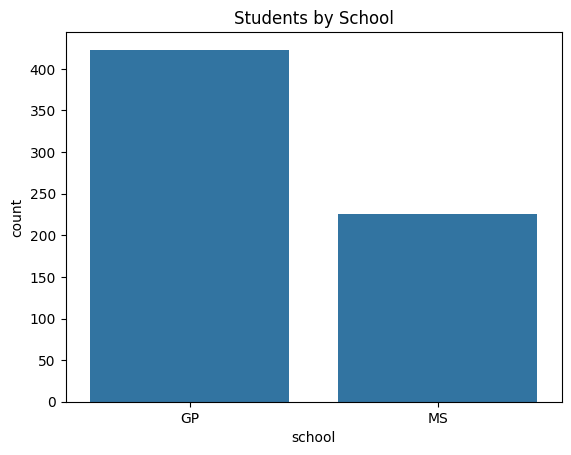

Final Shape: (649, 42)
Missing Values: 0
Duplicates: 0
Dataset prepared and saved successfully!


In [6]:
!pip install -q ucimlrepo

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

# 1. Load dataset
data = fetch_ucirepo(id=320)
df = pd.concat([data.data.features, data.data.targets], axis=1)

# 2. Inspect dataset
print(df.head())
print(df.info())
print(df.describe())

# 3. Check missing values
print(df.isnull().sum())

# 4. Handle missing values
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype == 'object':
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())

# 5. Remove duplicates
df.drop_duplicates(inplace=True)

# 6. EDA and visualization
print(df['school'].value_counts())

sns.histplot(df['age'], kde=True)
plt.title("Student Age Distribution")
plt.show()

sns.countplot(data=df, x='school')
plt.title("Students by School")
plt.show()

# 7. Encode categorical features
df = pd.get_dummies(df, drop_first=True, dtype=int)

# 8. Scale numerical features (excluding target G3)
cols = df.select_dtypes(include='number').columns.drop('G3')
scaler = StandardScaler()
df[cols] = scaler.fit_transform(df[cols])

# 9. Final verification
print("Final Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# 10. Save prepared dataset
df.to_csv("prepared_student_data.csv", index=False)

print("Dataset prepared and saved successfully!")